# 11. Después del entregable: todos los datos y otros modelos de la revisión

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** ¿Mejora el XGBoost geográfico si sus hiperparámetros se buscan con **todos los datos**? ¿Funcionan
mejor otros **modelos originales de la revisión bibliográfica** (Rotation Forest, stacking y RF + SVM)? ¿Son
**estadísticamente significativas** las diferencias?

**Respuesta corta.** Afinar el XGBoost geográfico con las 257 273 viviendas sube su F1 de validación de 0.572 a
0.581, pero en el test no mejora (0.566 frente a 0.585 con la configuración del Entregable 2), y su parte
geográfica no se distingue del XGBoost global. De los modelos originales de la revisión, el **Rotation Forest** es
el único que supera al modelo base en la validación y en el test (+0.099 de F1, IC 95 % [+0.024, +0.170]).
Estadísticamente, **la mejora sobre el modelo base es significativa** para todos los modelos con vecindad física,
originales o no (30 bloques espaciales: Friedman p = 2.6·10⁻⁵; Wilcoxon con Holm p < 0.01; efecto mediano a grande),
pero **ninguna diferencia entre ellos lo es**: ningún modelo original supera significativamente a los convencionales
que reciben la misma información.
```

Este capítulo recoge dos de los próximos pasos de la sección 10.6. Se hizo después de cerrar el pipeline
combinatorio, con todos los datos y el protocolo de la fase 2 del Entregable 2; el código está en `mejoras/`.

## 11.1 Por qué y cómo

**Dos motivos.**

1. **Los hiperparámetros del modelo nuevo nunca se buscaron con todos los datos.** En el Entregable 2 quedaron fijos
   (α = 0.75, 15 % de vecinos por ancla, profundidad 4) y en este entregable se buscaron con 10 001 viviendas, donde
   cada ancla tiene pocos vecinos y la búsqueda casi apagó los modelos locales (α = 0.97, sección 9.4).
2. **La revisión bibliográfica dejó otros candidatos.** Su Tabla III lista nueve modelos con evidencia de reducción
   de error que nunca se han aplicado a la clasificación del estrato con el catastro. El Entregable 2 eligió el
   primero, el XGBoost geográfico; aquí se prueban tres más: **Rotation Forest** (candidato 5), **RF + SVM en dos
   etapas** (candidato 4) y **stacking** (candidato 8). Bagged TAO Trees (3) no tiene una implementación abierta
   confiable en Python; GWO-XGBoost (2) y TPE-SVM (7) son métodos de optimización (el capítulo 3 mostró que los
   optimizadores empatan, y la SVM con optimización bayesiana TPE ya está en el pipeline); EFSHB (6) y NSGA-II (9)
   seleccionan variables, y aquí hay solo 35.

**Protocolo** (el de la fase 2 de la versión 3 del Entregable 2, sección 9.1):

- las 257 273 viviendas de entrenamiento y las variables de este entregable (modelo B + vecindad física, k = 8);
- los **mismos 5 pliegues kNNDM** de zonas nuevas del Entregable 2 v3 (q = 30). Es verificable: el modelo base
  vuelve a dar F1 0.460 y el XGBoost geográfico con la configuración del Entregable 2, 0.572, las cifras publicadas;
- los hiperparámetros se eligen con la media del F1 macro en esos pliegues, nunca con el test;
- el test de 7 bloques se mira **una sola vez**, al final, con IC 95 % BCa remuestreando bloques;
- el criterio de reemplazo del proyecto: diferencia pareada por pliegue mayor que un error estándar, y el test lo
  confirma.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from _comun import RAIZ

RM = RAIZ / "mejoras" / "resultados"
leer = lambda n: json.loads((RM / n).read_text(encoding="utf-8")) if (RM / n).exists() else None  # noqa: E731
GB, RV, MJ = leer("geo_busqueda.json"), leer("revision_cv.json"), leer("mejoras.json")
print("Resultados de mejoras/:", "completos" if GB and RV and MJ else "pendientes")

Resultados de mejoras/: completos


## 11.2 Hiperparámetros del XGBoost geográfico con todos los datos

**Una búsqueda factorizada.** La predicción del modelo es $p = \alpha\,p_{\text{global}} + (1-\alpha)\,p_{\text{local}}$
y sus dos partes se entrenan por separado, así que no hace falta reentrenar cada combinación. Se ajustaron 6
configuraciones del XGBoost global (profundidad 4 a 8, 300 o 600 árboles, con o sin pesos de clase) y 9 de los
modelos locales (fracción de vecinos por ancla de 2 % a 30 %, rejilla de anclas de 1 o 2 km, profundidad y árboles
de cada modelo local, con o sin pesos), y α se recorrió de 0 a 1 en pasos de 0.05 sobre las probabilidades ya
guardadas: 1 134 combinaciones con solo 75 ajustes. Con α = 1 el modelo es el XGBoost global, así que la misma
búsqueda da también el **XGBoost afinado**, la ablación sin la parte geográfica.

,global,local,α,F1 macro (validación),F1 por pliegue
0,G5,L5,0.50,0.5806,"0.587, 0.620, 0.446, 0.553, 0.696"
1,G4,L9,0.55,0.5799,"0.601, 0.618, 0.452, 0.560, 0.668"
2,G4,L5,0.50,0.5798,"0.579, 0.619, 0.449, 0.560, 0.693"
3,G2,L9,0.40,0.5796,"0.582, 0.640, 0.447, 0.556, 0.674"
4,G4,L9,0.60,0.5795,"0.599, 0.614, 0.458, 0.558, 0.670"
5,G2,L9,0.45,0.5791,"0.582, 0.636, 0.448, 0.553, 0.677"
6,G1_e2,L9,0.45,0.5790,"0.583, 0.637, 0.441, 0.555, 0.680"
7,G4,L9,0.50,0.5787,"0.598, 0.624, 0.444, 0.561, 0.667"


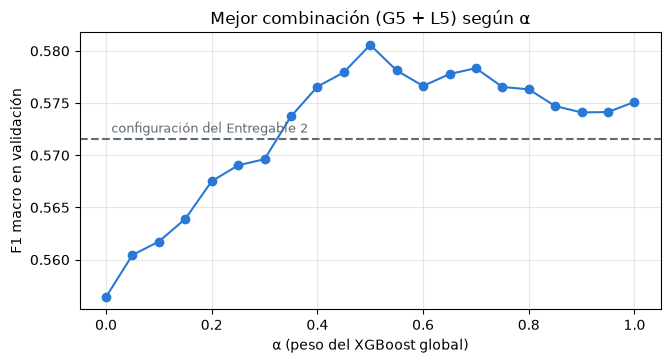

In [2]:
if GB:
    top = pd.DataFrame(GB["top20"][:8])
    top["F1 por pliegue"] = top.f1_pliegues.map(lambda v: ", ".join(f"{x:.3f}" for x in v))
    display(top[["global", "local", "alpha", "f1", "F1 por pliegue"]]
            .rename(columns={"alpha": "α", "f1": "F1 macro (validación)"}).round(4))
    curva = sorted((float(a), f) for a, f in GB["curva_alpha_mejor"].items())
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    ax.plot([a for a, _ in curva], [f for _, f in curva], marker="o", color="#2a78d6")
    ax.axhline(GB["referencia_E2"]["f1"], ls="--", color="#5F6B76")
    ax.text(0.01, GB["referencia_E2"]["f1"] + 0.0006, "configuración del Entregable 2", color="#5F6B76", fontsize=9)
    ax.set_xlabel("α (peso del XGBoost global)")
    ax.set_ylabel("F1 macro en validación")
    ax.set_title(f"Mejor combinación ({GB['mejor']['global']} + {GB['mejor']['local']}) según α")
    ax.grid(alpha=0.3)
    plt.show()
else:
    print("(búsqueda pendiente)")

**Lectura.** La mejor combinación usa un XGBoost global de profundidad 6 sin pesos de clase (G5) y modelos locales
en una rejilla de **1 km** (76 a 78 anclas) con el **5 % de los vecinos** por ancla, unas 10 000 viviendas (L5),
mezclados con **α = 0.5**: con todos los datos, los modelos locales sí reciben peso, a diferencia de la submuestra
(α = 0.97). Su F1 de validación es 0.581.

Dos señales de cautela. La superficie es plana: las ocho mejores combinaciones están entre 0.579 y 0.581. Y la
curva de α muestra que los modelos locales solos son peores (0.556 con α = 0), la mezcla llega a 0.581 y el XGBoost
global solo da 0.575: la parte geográfica aporta, en el mejor caso, medio punto de F1.

In [3]:
NOMBRES_GEO = ["XGBoost geográfico (configuración del E2)", "XGBoost geográfico afinado", "XGBoost afinado"]
if MJ:
    cv, te = MJ["cv"], MJ["test"]
    filas = {n: {"F1 validación": cv[n]["f1"], "F1 test": te[n]["f1"],
                 "IC 95 % test": f"[{te[n]['ic95_bca'][0]:.3f}, {te[n]['ic95_bca'][1]:.3f}]"} for n in NOMBRES_GEO}
    display(pd.DataFrame(filas).T.round(3))
    comp = {
        "afinado − configuración del E2 (validación)": cv["XGBoost geográfico afinado"]["vs_geo_E2"],
        "afinado − XGBoost afinado (validación)": cv["XGBoost geográfico afinado"]["vs_xgboost_afinado"],
    }
    display(pd.DataFrame({k: {"Δ F1": v["media"], "SE": v["SE"], "pliegues a favor": f"{v['pliegues_a_favor']}/5",
                              "¿> 1 SE?": "sí" if v["supera_1SE"] else "no"} for k, v in comp.items()}).T.round(3))
    t = te["XGBoost geográfico afinado"]["vs_xgboost_afinado"]
    print(f"Test, afinado − XGBoost afinado: {t['dif']:+.3f}, IC 95 % BCa [{t['ic95_bca'][0]:+.3f}, "
          f"{t['ic95_bca'][1]:+.3f}], {t['bloques_a_favor']} de {t['n_bloques']} bloques")

,F1 validación,F1 test,IC 95 % test
XGBoost geográfico (configuración del E2),0.571571,0.584825,"[0.530, 0.793]"
XGBoost geográfico afinado,0.580574,0.566132,"[0.509, 0.805]"
XGBoost afinado,0.575109,0.565366,"[0.522, 0.778]"


,Δ F1,SE,pliegues a favor,¿> 1 SE?
afinado − configuración del E2 (validación),0.009003,0.007122,4/5,sí
afinado − XGBoost afinado (validación),0.005465,0.005904,4/5,no


Test, afinado − XGBoost afinado: +0.001, IC 95 % BCa [-0.027, +0.068], 4 de 7 bloques


**Lectura.** En la validación, la búsqueda mejora a la configuración del Entregable 2 por +0.009 (SE 0.007, 4 de 5
pliegues), algo más de un error estándar; frente al XGBoost con el mismo modelo global, la parte geográfica aporta
+0.005 (SE 0.006), menos de un error estándar. **En el test la mejora no aparece:** el modelo afinado da 0.566,
por debajo de la configuración del Entregable 2 (0.585), y queda igual que el XGBoost afinado (+0.001, IC
[−0.027, +0.068], 4 de 7 bloques).

La lectura es la misma de los capítulos 9 y 10, ahora con más datos: la ganancia de validación es del tamaño del
ruido de elegir la mejor entre 1 134 combinaciones, y en zonas nuevas la parte geográfica no agrega F1 medible
sobre un XGBoost global con las mismas variables. La configuración del Entregable 2 sigue siendo la mejor versión
del modelo nuevo en el test.

## 11.3 Otros modelos originales de la revisión

- **Rotation Forest** (Rodríguez, Kuncheva y Alonso, 2006; candidato 5, Sartono et al., 2018). Cada árbol se entrena
  con las variables **rotadas**: se reparten al azar en grupos de M, en cada grupo se toma un subconjunto aleatorio
  de clases y el 75 % de sus filas, y los ejes del PCA de ese grupo forman un bloque de la matriz de rotación. La
  revisión lo propone por la colinealidad entre área, baños, habitaciones y sus promedios de vecindad. Implementación
  propia (`mejoras/modelos_revision.py`): 40 árboles, M ∈ {3, 6}, hojas mínimas ∈ {5, 20}.
- **RF + SVM en dos etapas** (candidato 4, Zhai et al., 2026). Un Random Forest ordena las variables por importancia
  y una SVM (Nyström + LinearSVC, con los hiperparámetros de la SVM finalista del capítulo 5) clasifica con las
  k ∈ {10, 20} más importantes. La misma SVM con todas las variables sirve de referencia: ¿ayuda la selección?
- **Stacking** (candidato 8, Sharma y Tomar, 2026). Un metamodelo (logística multinomial) combina las probabilidades
  fuera de muestra de la logística con vecindad, el XGBoost afinado y el Random Forest (S1), y además del XGBoost
  geográfico afinado (S2). En la validación, el metamodelo de cada pliegue se entrena con las predicciones de los
  **otros** pliegues; esas predicciones vienen de modelos que sí vieron el pliegue evaluado, lo que introduce un
  leve optimismo que el test no tiene.

La tabla reúne todos los modelos con la configuración que eligió su validación, frente al modelo base y frente a
la logística con las mismas variables de vecindad.

In [4]:
if MJ:
    base, lv = "Modelo base (logística B, sin vecindad)", "Logística con vecindad"
    ic = lambda v: f"[{v[0]:+.3f}, {v[1]:+.3f}]"  # noqa: E731
    filas = {}
    for n in sorted(te, key=lambda n: -te[n]["f1"]):
        c, t = cv[n], te[n]
        fila = {"F1 validación": round(c["f1"], 3), "F1 test": round(t["f1"], 3)}
        if n != base:
            vb, tb = c["vs_base"], t["vs_base"]
            fila.update({"vs base, validación (SE)": f"{vb['media']:+.3f} ({vb['SE']:.3f})",
                         "vs base, test [IC 95 %]": f"{tb['dif']:+.3f} {ic(tb['ic95_bca'])}",
                         "bloques": f"{tb['bloques_a_favor']}/7"})
        if n not in (base, lv):
            tl = t["vs_logistica_vecindad"]
            fila["vs logística con vecindad, test [IC 95 %]"] = f"{tl['dif']:+.3f} {ic(tl['ic95_bca'])}"
        filas[n] = fila
    display(pd.DataFrame(filas).T.fillna("—"))

,F1 validación,F1 test,"vs base, validación (SE)","vs base, test [IC 95 %]",bloques,"vs logística con vecindad, test [IC 95 %]"
Random Forest,0.576,0.601,+0.116 (0.039),"+0.108 [+0.022, +0.170]",6/7,"+0.027 [-0.009, +0.073]"
"Stacking S1 (logística, XGBoost, RF)",0.598,0.596,+0.138 (0.020),"+0.102 [-0.006, +0.173]",5/7,"+0.021 [-0.032, +0.080]"
Rotation Forest,0.598,0.593,+0.138 (0.029),"+0.099 [+0.024, +0.170]",6/7,"+0.018 [-0.019, +0.064]"
XGBoost geográfico (configuración del E2),0.572,0.585,+0.112 (0.029),"+0.092 [-0.024, +0.172]",5/7,"+0.011 [-0.045, +0.074]"
Logística con vecindad,0.575,0.574,+0.115 (0.017),"+0.081 [+0.003, +0.091]",6/7,—
Stacking S2 (S1 + XGBoost geográfico),0.583,0.568,+0.123 (0.017),"+0.075 [-0.053, +0.145]",5/7,"-0.007 [-0.061, +0.061]"
XGBoost geográfico afinado,0.581,0.566,+0.121 (0.032),"+0.073 [-0.119, +0.149]",5/7,"-0.008 [-0.111, +0.069]"
XGBoost afinado,0.575,0.565,+0.115 (0.031),"+0.072 [-0.015, +0.150]",5/7,"-0.009 [-0.046, +0.037]"
RF + SVM (dos etapas),0.553,0.517,+0.093 (0.030),"+0.024 [-0.060, +0.088]",4/7,"-0.057 [-0.148, +0.013]"
"Modelo base (logística B, sin vecindad)",0.46,0.493,—,—,—,—


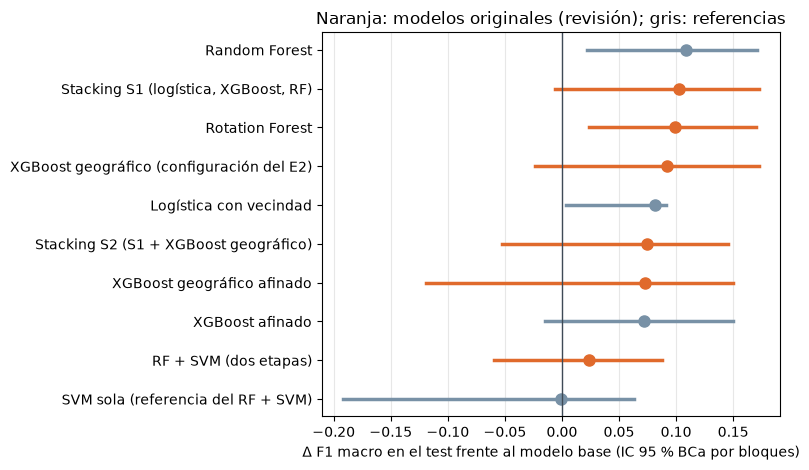

In [5]:
if MJ:
    nombres = [n for n in sorted(te, key=lambda n: te[n]["vs_base"]["dif"] if te[n]["vs_base"] else -1) if n != base]
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for i, n in enumerate(nombres):
        tb = te[n]["vs_base"]
        nuevo = n in ("Rotation Forest", "Stacking S1 (logística, XGBoost, RF)", "Stacking S2 (S1 + XGBoost geográfico)",
                      "RF + SVM (dos etapas)") or n.startswith("XGBoost geográfico")
        color = "#E06A2C" if nuevo else "#7891A6"
        ax.plot(tb["ic95_bca"], [i, i], color=color, lw=2.5)
        ax.plot(tb["dif"], i, "o", color=color, ms=8)
    ax.axvline(0, color="#3E4A56", lw=1)
    ax.set_yticks(range(len(nombres)))
    ax.set_yticklabels(nombres)
    ax.set_xlabel("Δ F1 macro en el test frente al modelo base (IC 95 % BCa por bloques)")
    ax.set_title("Naranja: modelos originales (revisión); gris: referencias")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

**Lectura.**

- **Rotation Forest:** es el único modelo original que cumple el criterio del proyecto frente al modelo base en las
  dos miradas: +0.138 en la validación (SE 0.029, 5 de 5 pliegues) y **+0.099 en el test, IC [+0.024, +0.170]**,
  ganando en 6 de los 7 bloques. Empata con el mejor en validación (0.598) y su test es 0.593.
- **Stacking:** S1 tiene la misma validación que el Rotation Forest (0.598), pero en el test su ventaja sobre el
  base (+0.102) tiene un intervalo que toca el 0 ([−0.006, +0.173]). Agregarle el XGBoost geográfico (S2) lo
  **empeora** en las dos miradas (0.583 y 0.568): sus probabilidades no traen información nueva para el metamodelo.
- **RF + SVM:** supera al base en la validación (+0.093), pero no en el test (+0.024, IC [−0.060, +0.088]). La
  selección de variables del Random Forest sí ayuda a la SVM (test 0.517 frente a 0.493 con todas las variables),
  pero la SVM queda por debajo de los ensambles de árboles, como en el capítulo 5.
- **Frente a la logística con las mismas variables de vecindad, ningún modelo se confirma en el test.** El Rotation
  Forest y el stacking S1 la superan en la validación por apenas un error estándar (+0.023, SE 0.023 y 0.022), y en
  el test sus intervalos incluyen el 0 (+0.018 [−0.019, +0.064] y +0.021 [−0.032, +0.080]). El Random Forest de la
  guía, que no es original, tiene el mejor F1 de test (0.601).

## 11.4 ¿Son estadísticamente significativas las diferencias?

Con 11 modelos hay 55 pares posibles, así que se sigue la secuencia jerárquica del capítulo 7: una prueba global,
después comparaciones dirigidas con corrección por comparaciones múltiples (Holm dentro de cada familia) y siempre
el tamaño del efecto. Se miran tres unidades de réplica, de la más a la menos potente:

1. **30 bloques espaciales de 2 km** del entrenamiento (los que tienen al menos 200 viviendas, de 34): el F1 macro
   de las predicciones fuera de muestra en cada bloque. Friedman → Nemenyi → Wilcoxon de rangos con signo, delta de
   Cliff. Es la misma unidad que usó el capítulo 7.
2. **5 pliegues kNNDM:** t de Student pareada **corregida de Nadeau y Bengio (2003)**, que infla la varianza porque
   los pliegues comparten entrenamiento.
3. **7 bloques de test:** prueba exacta de permutación por cambio de signo de las diferencias por bloque. Con 7
   bloques el p-valor más pequeño posible es 2/128 = 0.016, y con 10 comparaciones Holm exige 0.005 para la primera:
   **el test no puede declarar significancia después de la corrección**; sirve para confirmar la dirección y el
   intervalo.

Friedman sobre 30 bloques de 2 km: χ² = 39.0, gl = 10, p = 2.6e-05; diferencia crítica de Nemenyi = 2.76 rangos


,rango medio,Nemenyi p vs base,Nemenyi p vs logística con vecindad
Logística con vecindad,6.117,0.2153,1.0000
"Modelo base (logística B, sin vecindad)",8.400,1.0000,0.2153
RF + SVM (dos etapas),6.550,0.5334,1.0000
Random Forest,5.250,0.0107,0.9954
Rotation Forest,5.617,0.0454,1.0000
SVM sola (referencia del RF + SVM),7.617,0.9980,0.8084
"Stacking S1 (logística, XGBoost, RF)",6.033,0.1722,1.0000
Stacking S2 (S1 + XGBoost geográfico),5.767,0.0763,1.0000
XGBoost afinado,4.867,0.0018,0.9328
XGBoost geográfico (configuración del E2),5.183,0.0080,0.9917


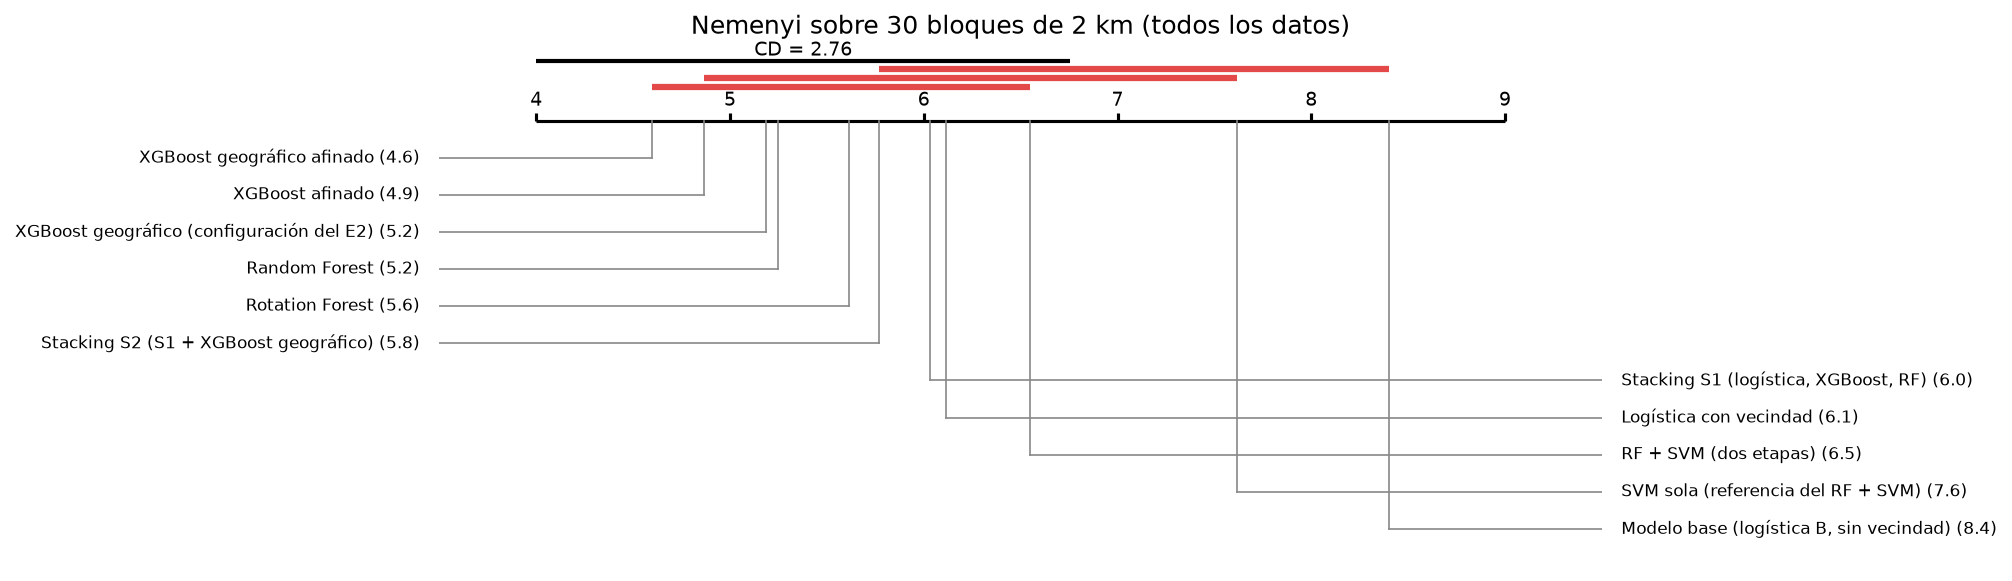

VS MODELO BASE


,bloques a favor,Wilcoxon p (Holm),δ de Cliff,pliegues: t corregida p (Holm),test: permutación p (Holm)
Logística con vecindad,21/30,0.0008 (0.0069),+0.35 (mediano),0.011 (0.085),0.031 (0.312)
XGBoost afinado,21/30,0.0012 (0.0094),+0.48 (grande),0.070 (0.360),0.062 (0.438)
XGBoost geográfico (configuración del E2),20/30,0.0013 (0.0094),+0.43 (mediano),0.060 (0.360),0.062 (0.438)
XGBoost geográfico afinado,21/30,0.0004 (0.0041),+0.51 (grande),0.068 (0.360),0.125 (0.438)
Random Forest,22/30,0.0014 (0.0094),+0.43 (mediano),0.120 (0.360),0.031 (0.312)
Rotation Forest,21/30,0.0023 (0.0094),+0.45 (mediano),0.035 (0.242),0.031 (0.312)
RF + SVM (dos etapas),20/30,0.0817 (0.1004),+0.31 (pequeño),0.106 (0.360),0.688 (1.000)
SVM sola (referencia del RF + SVM),20/30,0.0502 (0.1004),+0.18 (pequeño),0.073 (0.360),0.688 (1.000)
"Stacking S1 (logística, XGBoost, RF)",22/30,0.0026 (0.0094),+0.44 (mediano),0.009 (0.085),0.062 (0.438)
Stacking S2 (S1 + XGBoost geográfico),22/30,0.0012 (0.0094),+0.43 (mediano),0.008 (0.078),0.094 (0.438)


VS LOGÍSTICA CON VECINDAD


,bloques a favor,Wilcoxon p (Holm),δ de Cliff,pliegues: t corregida p (Holm),test: permutación p (Holm)
XGBoost afinado,16/30,0.1635 (1.0000),+0.21 (pequeño),0.999 (1.000),0.406 (1.000)
XGBoost geográfico (configuración del E2),16/30,0.1945 (1.0000),+0.18 (pequeño),0.934 (1.000),0.344 (1.000)
XGBoost geográfico afinado,16/30,0.0609 (0.5484),+0.24 (pequeño),0.908 (1.000),0.469 (1.000)
Random Forest,15/30,0.3130 (1.0000),+0.14 (despreciable),0.992 (1.000),0.219 (1.000)
Rotation Forest,15/30,0.2645 (1.0000),+0.15 (pequeño),0.539 (1.000),0.156 (1.000)
RF + SVM (dos etapas),16/30,0.8372 (1.0000),-0.04 (despreciable),0.559 (1.000),0.047 (0.422)
SVM sola (referencia del RF + SVM),12/30,0.1072 (0.8576),-0.16 (pequeño),0.483 (1.000),0.062 (0.500)
"Stacking S1 (logística, XGBoost, RF)",15/30,0.6653 (1.0000),+0.07 (despreciable),0.535 (1.000),0.562 (1.000)
Stacking S2 (S1 + XGBoost geográfico),15/30,0.3389 (1.0000),+0.11 (despreciable),0.789 (1.000),0.844 (1.000)


DIRIGIDAS


,bloques a favor,Wilcoxon p (Holm),δ de Cliff,pliegues: t corregida p (Holm),test: permutación p (Holm)
XGBoost geográfico afinado − XGBoost afinado,12/30,0.5057 (1.0000),+0.02 (despreciable),0.571 (0.628),0.750 (1.000)
Rotation Forest − XGBoost geográfico (configuración del E2),11/30,0.6309 (1.0000),-0.03 (despreciable),0.314 (0.628),0.688 (1.000)


In [6]:
ESt = leer("estadistica.json")
if ESt:
    fr = ESt["friedman"]
    print(f"Friedman sobre {ESt['bloques']['n_usados']} bloques de 2 km: χ² = {fr['chi2']:.1f}, gl = {fr['gl']}, "
          f"p = {fr['p']:.1e}; diferencia crítica de Nemenyi = {fr['cd']:.2f} rangos")
    rangos = pd.Series(fr["rangos"]).rename("rango medio (1 = mejor)")
    nem = pd.DataFrame(ESt["nemenyi_p"])
    display(pd.DataFrame({"rango medio": rangos,
                          "Nemenyi p vs base": nem["Modelo base (logística B, sin vecindad)"],
                          "Nemenyi p vs logística con vecindad": nem["Logística con vecindad"]}).round(4))
    from IPython.display import Image
    ruta_cd = RM / "figuras" / "cd_mejoras.png"
    if ruta_cd.exists():
        display(Image(filename=str(ruta_cd)))

    def tabla_comp(fam):
        filas = {}
        for r in ESt["comparaciones"][fam]:
            filas[r["a"] if fam != "dirigidas" else f"{r['a']} − {r['b']}"] = {
                "bloques a favor": f"{r['bloques_a_favor']}/{r['n_bloques']}",
                "Wilcoxon p (Holm)": f"{r['wilcoxon_p']:.4f} ({r['wilcoxon_p_holm']:.4f})",
                "δ de Cliff": f"{r['delta_cliff']:+.2f} ({r['magnitud']})",
                "pliegues: t corregida p (Holm)": f"{r['cv_p']:.3f} ({r['cv_p_holm']:.3f})",
                "test: permutación p (Holm)": f"{r['test_perm_p']:.3f} ({r['test_perm_p_holm']:.3f})"}
        return pd.DataFrame(filas).T

    for fam in ("vs modelo base", "vs logística con vecindad", "dirigidas"):
        print(fam.upper())
        display(tabla_comp(fam))
else:
    print("(pruebas de significancia pendientes)")

**Lectura.**

- **Hay diferencias entre los modelos** (Friedman χ² = 39.0, gl = 10, p = 2.6·10⁻⁵).
- **Frente al modelo base, la mejora es significativa para todos los modelos con vecindad física**, originales y
  de referencia: XGBoost geográfico (afinado y del E2), Rotation Forest, los dos stacking, XGBoost, Random Forest y
  la logística con vecindad (Wilcoxon con Holm, p entre 0.004 y 0.009). El efecto es **mediano a grande**: δ de Cliff
  entre 0.35 (logística con vecindad) y 0.51 (XGBoost geográfico afinado, el de mejor rango medio, 4.6). Nemenyi, que
  compara los 55 pares a la vez y es más conservador, confirma la diferencia para el XGBoost geográfico (p = 0.0005
  el afinado, 0.008 el del E2), XGBoost, Random Forest y Rotation Forest (p = 0.045). El RF + SVM y la SVM sola no
  superan significativamente al base (p de Holm 0.10).
- **Entre los modelos que reciben la misma vecindad, ninguna diferencia es significativa.** Frente a la logística
  con vecindad, todos los p de Holm son ≥ 0.54 y los efectos, despreciables o pequeños (|δ| ≤ 0.24). La parte
  geográfica del modelo nuevo frente al XGBoost afinado: δ = +0.02, p = 1. Rotation Forest frente al XGBoost
  geográfico del E2: δ = −0.03, p = 1.
- **Con las unidades menos potentes nada sobrevive a la corrección.** Con la t corregida sobre los 5 pliegues, los
  p crudos frente al base van de 0.008 a 0.12, pero con Holm ninguno baja de 0.05 (el menor, 0.078). En el test, los
  p crudos de la permutación son 0.031 para el Rotation Forest, el Random Forest y la logística con vecindad, y 0.31
  después de Holm, como se anticipó.

## 11.5 Conclusión

```{admonition} Qué se puede afirmar con rigor estadístico
:class: important
1. **Los modelos con vecindad física superan al modelo base en zonas nuevas, con significancia estadística y un
   efecto mediano a grande**, en la prueba con más potencia (30 bloques espaciales, Wilcoxon con Holm, p < 0.01). Eso
   incluye al **modelo nuevo del proyecto, el XGBoost geográfico** (δ = 0.51 afinado, 0.43 con la configuración del
   Entregable 2) y a otro modelo original de la revisión, el **Rotation Forest** (δ = 0.45), que además es el único
   original cuyo intervalo de test frente al base excluye el 0 (+0.099, IC [+0.024, +0.170]).
2. **Ningún modelo original supera significativamente a los modelos convencionales que reciben la misma
   información**, en ninguna de las tres miradas. El aporte que sí es significativo es el de la **vecindad física**,
   no el de un algoritmo en particular.
3. **Afinar el XGBoost geográfico con todos los datos no mejora su test**, y su parte geográfica no agrega F1 medible
   sobre el XGBoost global en zonas nuevas.
4. **Límite del diseño:** con 7 bloques de test ninguna diferencia puede ser significativa después de corregir por
   comparaciones múltiples; las conclusiones firmes salen de los bloques espaciales de la validación y del acuerdo
   de dirección con el test.
```

**Sobre la respuesta del capítulo 9.** El XGBoost geográfico sigue superando al modelo base en zonas nuevas con
la submuestra (+0.094, IC BCa [+0.042, +0.147], sección 9.3). Con todos los datos, la configuración del Entregable 2
da +0.092 y la afinada +0.073, pero con el intervalo BCa de este entregable ninguna de las dos excluye el 0
([−0.024, +0.172] y [−0.119, +0.149]).

**Sobre el intervalo del Entregable 2.** El Entregable 2 publicó para la configuración del XGBoost geográfico
+0.092 con IC [+0.034, +0.199], calculado con bootstrap de percentiles sobre los 7 bloques. La cifra puntual se
reproduce exactamente; con el método BCa que usa este entregable, el intervalo es [−0.024, +0.172]. Con solo 7
bloques de test, los dos métodos son aproximaciones gruesas y la confirmación de esa diferencia **depende del método
del intervalo**.

**Sobre las comparaciones múltiples.** El test se miró una sola vez, pero se comparan 10 modelos con el base. El
intervalo del Rotation Forest excluye el 0 con margen pequeño (+0.024 en su extremo inferior), así que conviene
leerlo como evidencia favorable, no como prueba concluyente.

## 11.6 Reproducir

Desde la carpeta del Entregable 3, con `PYTHONPATH` apuntando a ella y a `mejoras/`:

```
..\venv_e2\Scripts\python -u mejoras\01_geo_busqueda.py   # búsqueda del XGBoost geográfico (≈ 3 h)
..\venv_e2\Scripts\python -u mejoras\02_revision.py       # modelos de la revisión y rivales (≈ 2 h)
..\venv_e2\Scripts\python -u mejoras\03_test.py           # stacking, comparaciones y test (≈ 2 h)
..\venv_e2\Scripts\python -u mejoras\04_estadistica.py    # Friedman, Nemenyi, Wilcoxon, t corregida, Holm (≈ 15 min)
```

Los tiempos son de un portátil de 4 núcleos con 3 procesos; las probabilidades de cada pliegue quedan en
`mejoras/chk/` y los scripts se reanudan solos. Los resultados están en `mejoras/resultados/` y el detalle del
protocolo en `mejoras/README.md`.